In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from warnings import filterwarnings
filterwarnings('ignore')

In [5]:
insurance =pd.read_csv("/content/new_insurance_data.csv")

In [6]:
insurance.head()

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
0,18.0,male,23.21,0.0,no,29087.54313,17.0,715428.0,4720920.992,0.0,55784970.05,southeast,1121.8739
1,18.0,male,30.14,0.0,no,39053.67437,7.0,699157.0,4329831.676,0.0,13700885.19,southeast,1131.5066
2,18.0,male,33.33,0.0,no,39023.62759,19.0,702341.0,6884860.774,0.0,73523107.27,southeast,1135.9407
3,18.0,male,33.66,0.0,no,28185.39332,11.0,700250.0,4274773.550,0.0,75819679.60,southeast,1136.3994
4,18.0,male,34.10,0.0,no,14697.85941,16.0,711584.0,3787293.921,0.0,23012320.01,southeast,1137.0110


In [7]:
a = insurance.shape
print(f'Rows: {a[0]} and Columns: {a[1]}')

Rows: 1338 and Columns: 13


In [8]:
insurance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 13 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   age                              1329 non-null   float64
 1   sex                              1338 non-null   object 
 2   bmi                              1335 non-null   float64
 3   children                         1333 non-null   float64
 4   smoker                           1338 non-null   object 
 5   Claim_Amount                     1324 non-null   float64
 6   past_consultations               1332 non-null   float64
 7   num_of_steps                     1335 non-null   float64
 8   Hospital_expenditure             1334 non-null   float64
 9   NUmber_of_past_hospitalizations  1336 non-null   float64
 10  Anual_Salary                     1332 non-null   float64
 11  region                           1338 non-null   object 
 12  charges             

**Insights**
* there are some null values
* we have 3 object data types (need to convert numeric)

In [9]:
insurance.isnull().sum()

,0
age,9
sex,0
bmi,3
children,5
smoker,0
Claim_Amount,14
past_consultations,6
num_of_steps,3
Hospital_expenditure,4
NUmber_of_past_hospitalizations,2


In [10]:
insurance.isnull().sum().sum()

np.int64(52)

**To drop null values**
*df.dropna(inplace= True)

# **Data imputation**

In [12]:
col = list(insurance.columns)
col

['age',
 'sex',
 'bmi',
 'children',
 'smoker',
 'Claim_Amount',
 'past_consultations',
 'num_of_steps',
 'Hospital_expenditure',
 'NUmber_of_past_hospitalizations',
 'Anual_Salary',
 'region',
 'charges']

In [13]:
insurance.describe()

,age,bmi,children,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,charges
count,1329.000000,1335.000000,1333.000000,1324.000000,1332.000000,1.335000e+03,1.334000e+03,1336.000000,1.332000e+03,1338.000000
mean,39.310008,30.665112,1.090773,33361.327180,15.216216,9.100047e+05,1.584179e+07,1.060629,3.696849e+08,13270.422265
std,14.034818,6.101690,1.201856,15617.288337,7.467723,9.188612e+04,2.669305e+07,0.533583,5.668843e+08,12110.011237
min,18.000000,15.960000,0.000000,1920.136268,1.000000,6.954300e+05,2.945253e+04,0.000000,2.747072e+06,1121.873900
25%,27.000000,26.302500,0.000000,20768.860390,9.000000,8.471995e+05,4.077633e+06,1.000000,7.701932e+07,4740.287150
50%,39.000000,30.400000,1.000000,33700.310675,15.000000,9.143000e+05,7.490337e+06,1.000000,1.419361e+08,9382.033000
75%,51.000000,34.687500,2.000000,45052.331957,20.000000,9.716840e+05,1.084082e+07,1.000000,3.243499e+08,16639.912515
max,64.000000,53.130000,5.000000,77277.988480,40.000000,1.107872e+06,2.616317e+08,3.000000,4.117197e+09,63770.428010


In [14]:
insurance.describe(include = 'O')

,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


In [15]:
insurance['children'].mode()

,children
0,0.0


In [16]:
for cname in col:
  if cname == 'children':
    insurance[cname] = insurance[cname].fillna(insurance[cname].mode()[0])
  elif insurance[cname].dtype == 'object':
    insurance[cname] = insurance[cname].fillna(insurance[cname].mode()[0])
  else:
    insurance[cname] = insurance[cname].fillna(insurance[cname].mean())

In [17]:
insurance.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
Claim_Amount,0
past_consultations,0
num_of_steps,0
Hospital_expenditure,0
NUmber_of_past_hospitalizations,0


**Outlier Analysis**

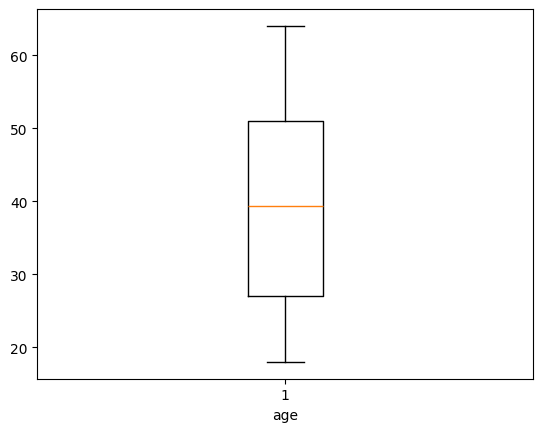

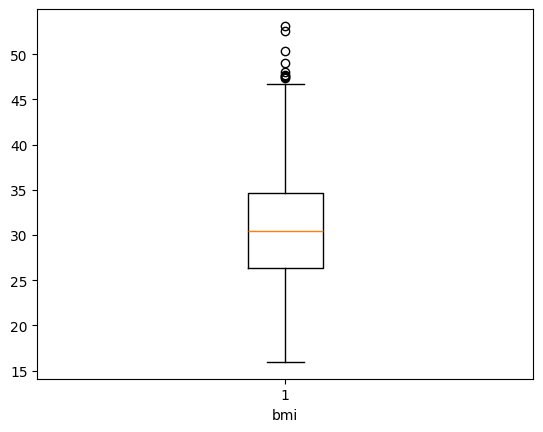

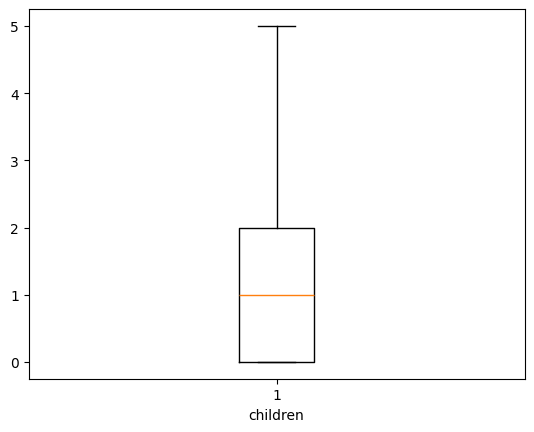

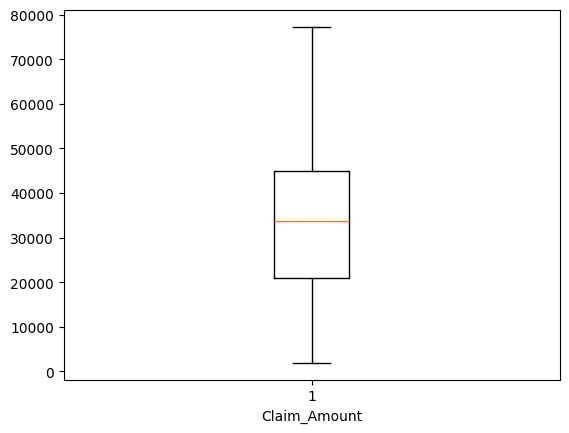

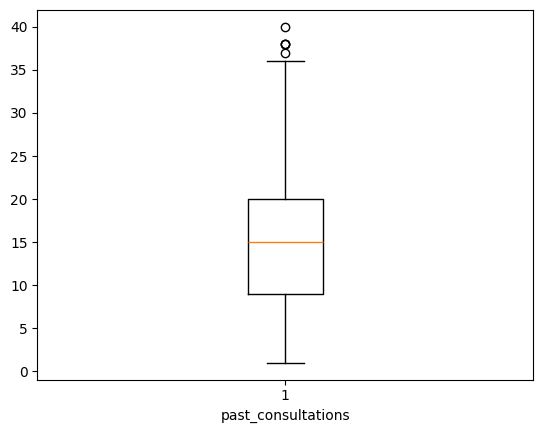

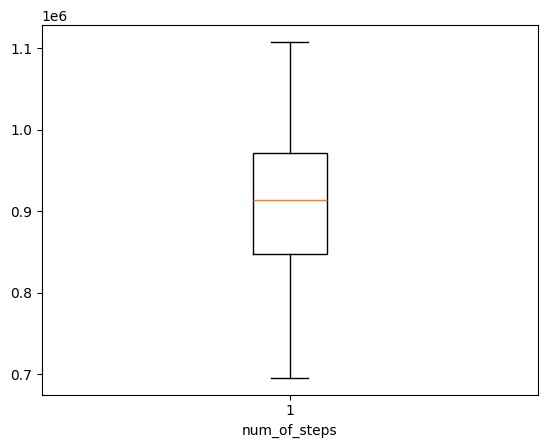

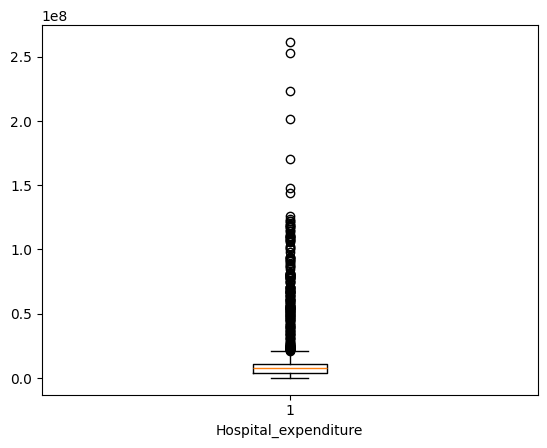

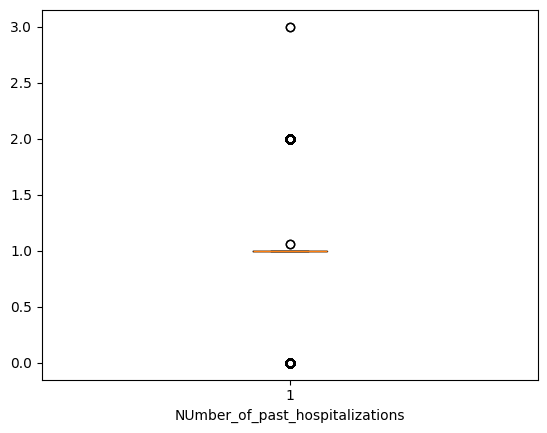

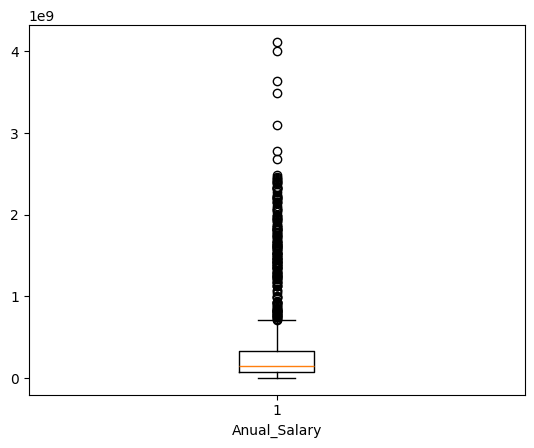

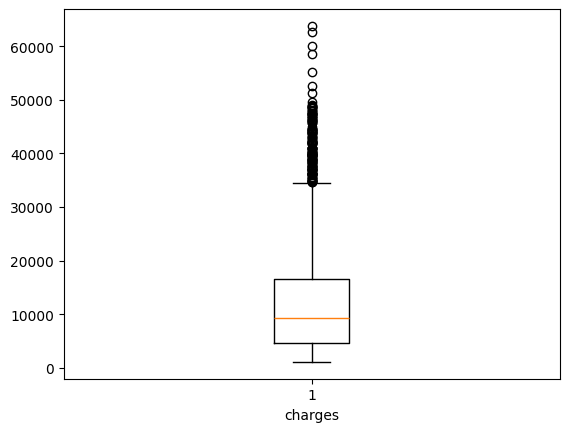

In [18]:
for cname in col:
  if insurance[cname].dtype == 'float64':
    plt.boxplot(insurance[cname])
    plt.xlabel(cname)
    plt.show()

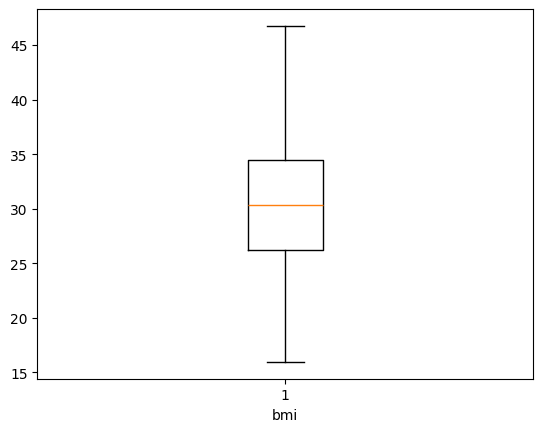

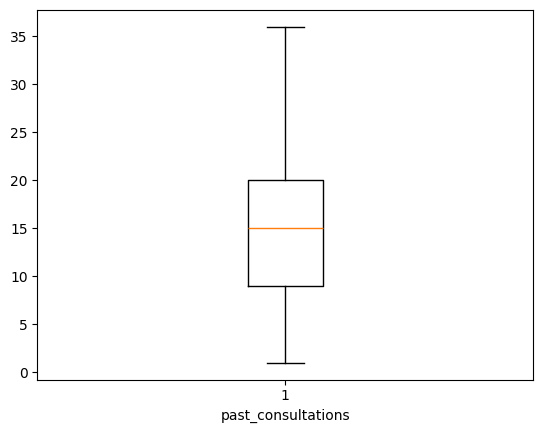

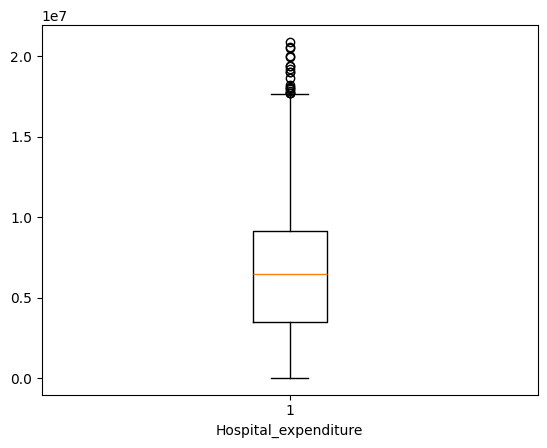

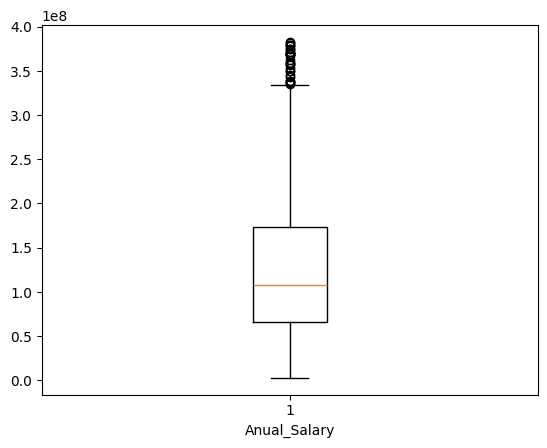

In [19]:
outCols = ['bmi','past_consultations','Hospital_expenditure','Anual_Salary']

for col in outCols:
  q1 = insurance[col].quantile(0.25)
  q3 = insurance[col].quantile(0.75)
  IQR = q3 - q1
  lowerFence = q1 - (1.5*IQR)
  upperFence = q3 + (1.5*IQR)

  insurance = insurance[(insurance[col]>= lowerFence) & (insurance[col]<=upperFence)]

  plt.boxplot(insurance[col])
  plt.xlabel(col)
  plt.show()

In [20]:
insurance.shape

(1030, 13)

In [21]:
corrMat = insurance.corr(numeric_only=True)
corrMat

,age,bmi,children,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,charges
age,1.000000,0.155957,0.047664,0.117750,0.172063,0.749468,0.160555,0.519538,0.490802,0.676071
bmi,0.155957,1.000000,0.003515,0.008343,0.023543,0.040324,0.013992,0.016121,0.004105,0.010248
children,0.047664,0.003515,1.000000,0.044480,0.046549,0.229850,-0.005459,0.314249,0.067953,0.140763
Claim_Amount,0.117750,0.008343,0.044480,1.000000,0.071569,0.185434,0.054111,0.109748,0.157826,0.192601
past_consultations,0.172063,0.023543,0.046549,0.071569,1.000000,0.259401,0.088466,0.135498,0.265710,0.278131
num_of_steps,0.749468,0.040324,0.229850,0.185434,0.259401,1.000000,0.299554,0.714983,0.767247,0.936946
Hospital_expenditure,0.160555,0.013992,-0.005459,0.054111,0.088466,0.299554,1.000000,0.129334,0.366809,0.358378
NUmber_of_past_hospitalizations,0.519538,0.016121,0.314249,0.109748,0.135498,0.714983,0.129334,1.000000,0.359422,0.538116
Anual_Salary,0.490802,0.004105,0.067953,0.157826,0.265710,0.767247,0.366809,0.359422,1.000000,0.892308
charges,0.676071,0.010248,0.140763,0.192601,0.278131,0.936946,0.358378,0.538116,0.892308,1.000000


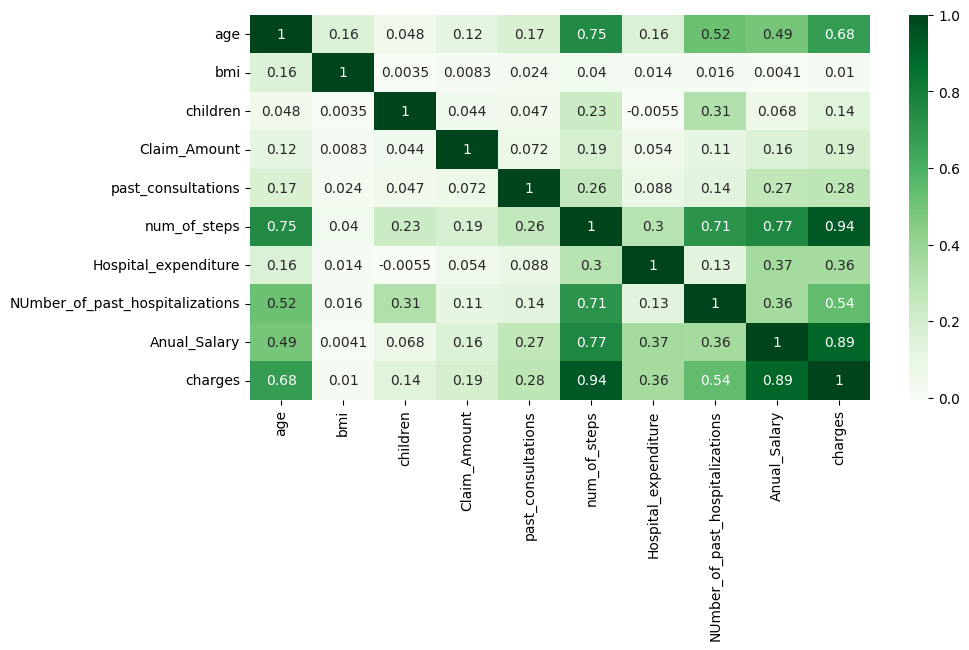

In [22]:
plt.figure(figsize = (10,5))
sns.heatmap(corrMat, annot = True, cmap = 'Greens')
plt.show()

**Insight**

*Data processing Encoding*

In [23]:
from sklearn.preprocessing import LabelEncoder

In [24]:
cat_col = insurance.select_dtypes(include=['object']).columns
cat_col

Index(['sex', 'smoker', 'region'], dtype='object')

In [25]:
le = LabelEncoder()

In [26]:
for col in cat_col:
  insurance[col] = le.fit_transform(insurance[col])

In [27]:
insurance.head()

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
0,18.0,1,23.21,0.0,0,29087.54313,17.0,715428.0,4720920.992,0.0,55784970.05,2,1121.8739
1,18.0,1,30.14,0.0,0,39053.67437,7.0,699157.0,4329831.676,0.0,13700885.19,2,1131.5066
2,18.0,1,33.33,0.0,0,39023.62759,19.0,702341.0,6884860.774,0.0,73523107.27,2,1135.9407
3,18.0,1,33.66,0.0,0,28185.39332,11.0,700250.0,4274773.550,0.0,75819679.60,2,1136.3994
4,18.0,1,34.10,0.0,0,14697.85941,16.0,711584.0,3787293.921,0.0,23012320.01,2,1137.0110


**Dependant and Independant data segregation**

In [28]:
x = insurance.drop('charges',axis = 1) # Here, all are independent features
x.shape

(1030, 12)

In [29]:
y = insurance['charges'] # Dependent column
y.shape

(1030,)

**Standerdize the data**

In [30]:
from sklearn.preprocessing import StandardScaler

In [31]:
st = StandardScaler()

In [32]:
x_scaled = st.fit_transform(x)
x = pd.DataFrame(x_scaled,columns = x.columns, index = x.index)

In [33]:
x.head()

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region
0,-1.473944,1.031566,-1.172917,-0.873205,-0.213741,-0.082463,0.673707,-2.299541,-0.394595,-2.441165,-0.867555,0.425936
1,-1.473944,1.031566,-0.014853,-0.873205,-0.213741,0.613867,-1.005702,-2.535609,-0.516107,-2.441165,-1.381301,0.425936
2,-1.473944,1.031566,0.518224,-0.873205,-0.213741,0.611768,1.009589,-2.489414,0.277745,-2.441165,-0.651015,0.425936
3,-1.473944,1.031566,0.573370,-0.873205,-0.213741,-0.145496,-0.333939,-2.519752,-0.533213,-2.441165,-0.622979,0.425936
4,-1.473944,1.031566,0.646897,-0.873205,-0.213741,-1.087866,0.505766,-2.355312,-0.684674,-2.441165,-1.267630,0.425936


**Splitting  the data**

In [35]:
from sklearn.model_selection import train_test_split

In [36]:
x_train, x_test, y_train, y_test = train_test_split(x,y,train_size=0.8,random_state = 42)

In [37]:
x_train.shape , x_test.shape

((824, 12), (206, 12))

In [38]:
y_train.shape , y_test.shape

((824,), (206,))

**Building a model**

In [39]:
from sklearn.linear_model import LinearRegression

In [40]:
model = LinearRegression()

In [41]:
model.fit(x_train,y_train)

LinearRegression()

In [42]:
y_pred = model.predict(x_test)
y_pred

array([ 1423.38585065,  1469.96666143,  2687.29423957,  1860.70799901,
       13873.65968554, 18812.58037877, 11543.47370714,  3774.05205416,
        4146.38985802,  8206.43129433, 12768.02704653,  8493.84565613,
         870.18786135,  2697.6601722 ,  6723.6993969 ,  8076.38501362,
       11686.59503835,  8929.38375826, 10824.13785857,  6114.42786235,
        7811.27848104,  5793.32800713,  5114.04627051,  8382.7404034 ,
        5318.96099292,  4773.64641002,  9196.58309195, 13508.48085814,
        7237.84964507,  8116.76054907,  6007.84697829,  7509.70124565,
       10538.10743252,  5866.13915503,  5652.10122743,   863.41839838,
        4290.78066415, 13722.12194031,  8903.63639026,  4441.11805917,
        9143.11838262,  9833.20511254, -1614.85463273,  8698.05403982,
        3456.49146713,  3616.22828635,  5463.37620967,  9763.99381358,
       11785.23186704, 10599.91306276, 12370.58614768,  9822.49515813,
       12723.13048789,  8368.47332957,  4868.23869013,   493.63828728,
      

In [44]:
from sklearn.metrics import r2_score, root_mean_squared_error

In [45]:
root_mean_squared_error(y_test, y_pred)

784.3067317594656

In [46]:
r2_score(y_test,y_pred)

0.9694621830372167

**we are getting 96% model score of data**

In [47]:
model.coef_ # m --> Slope

array([ 5.56826729e+02, -6.09752361e+01, -2.20394857e+01,  2.95054877e+01,
        5.52420909e+02,  2.05394445e+01,  2.07803927e+00,  2.80530045e+03,
        5.04238775e+01, -4.61725963e+02,  1.34872046e+03, -4.64399714e+01])

In [48]:
model.intercept_ # C -->

np.float64(7653.117243415395)

**For plotting Best Fit Line**

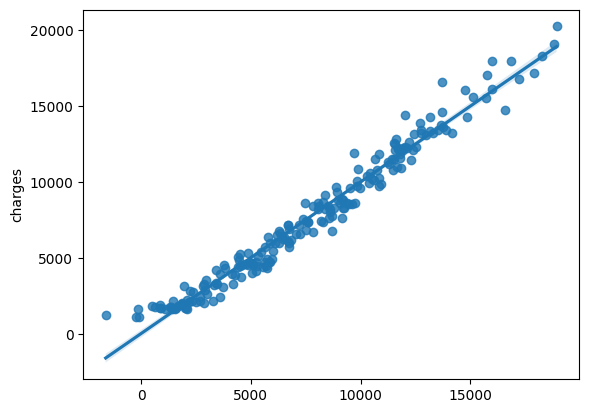

In [49]:
sns.regplot(x = y_pred, y = y_test)
plt.show()